In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, pipeline, set_seed)

SEED = 42
set_seed(SEED)
pd.set_option("display.max_colwidth", 100)

if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

print(f"DEVICE: {DEVICE}")

MODELO_INGLES = "distilbert-base-uncased"
MODELO_ESPANOL = "dccuchile/distilbert-base-spanish-uncased"

d:\Users\ClientAdm\Documents\datascience-g8\01-python-intro\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DEVICE: cpu


In [7]:
DATA_PATH = Path("../data/intenciones_asistente_es.csv")

if not DATA_PATH.exists():
    print("Descargando el dataset...")
    url = "https://huggingface.co/datasets/mteb/MassiveIntentClassification/resolve/main/es/{}-00000-of-00001.parquet"
    partes = [pd.read_parquet(url.format(parte)).assign(split=parte) for parte in ["train", "test"]]
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.concat(partes, ignore_index=True).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(f"Frases: {len(df)} | intenciones: {df['label'].nunique()}")
df.sample(8, random_state=SEED)

Frases: 14488 | intenciones: 60


,text,label,split
8710,deberías saber sobre,qa_factoid,train
11899,apaga las luces ahora,iot_hue_lightoff,test
2366,cómo está el tiempo hoy en burgos,weather_query,train
6292,me gustaría escuchar noventa y nueve punto cinco,play_radio,train
169,solo muéstrame alguna noticias de b. b. c.,news_query,train
2034,qué hay de nuevo en el mercado de valores,qa_stock,train
10078,cuál es el tipo de cambio de la moneda inglesa al yen,qa_currency,train
1944,hora de madrid,datetime_query,train


In [8]:
INTENCIONES = {
    "alarm_set": "poner_alarma",
    "calendar_set": "agendar_evento",
    "weather_query": "consultar_clima",
    "play_music": "poner_musica",
    "cooking_recipe": "buscar_receta",
    "takeaway_order": "pedir_comida",
    "transport_taxi": "pedir_taxi",
    "iot_hue_lightoff": "apagar_luces",
}

# a) Filtrar y traducir intenciones
df_int = df[df["label"].isin(INTENCIONES)].copy()
df_int["intencion"] = df_int["label"].map(INTENCIONES)

# b) Crear diccionarios de etiquetas
ETIQUETAS = {i: nombre for i, nombre in enumerate(sorted(INTENCIONES.values()))}
ETIQUETA_A_ID = {nombre: i for i, nombre in ETIQUETAS.items()}

# Reemplazar columna label por su ID numérico
df_int["label"] = df_int["intencion"].map(ETIQUETA_A_ID)

# c) Separar en train y test
columnas = ["text", "intencion", "label"]
train_df = df_int[df_int["split"] == "train"][columnas].reset_index(drop=True)
test_df = df_int[df_int["split"] == "test"][columnas].reset_index(drop=True)

print(ETIQUETAS)
print(f"\nEntrenamiento: {len(train_df)} | prueba: {len(test_df)}")
print("\nFrases de entrenamiento por intención:")
print(train_df["intencion"].value_counts())

{0: 'agendar_evento', 1: 'apagar_luces', 2: 'buscar_receta', 3: 'consultar_clima', 4: 'pedir_comida', 5: 'pedir_taxi', 6: 'poner_alarma', 7: 'poner_musica'}

Entrenamiento: 2799 | prueba: 742

Frases de entrenamiento por intención:
intencion
agendar_evento     810
poner_musica       639
consultar_clima    573
buscar_receta      207
poner_alarma       182
apagar_luces       153
pedir_comida       135
pedir_taxi         100
Name: count, dtype: int64


In [9]:
train_df.groupby("intencion").sample(1, random_state=SEED)

,text,intencion,label
1866,envía una notificación a amigo,agendar_evento,0
1170,apaga las luces de la habitación en diez segundos,apagar_luces,1
2576,comidas sanas,buscar_receta,2
1178,hace calor y bochorno o cálido y húmedo en el pantano hoy,consultar_clima,3
2791,dame las mejores ofertas de pizza del día de hoy,pedir_comida,4
2704,llamar a un taxi,pedir_taxi,5
1730,poner una alarma recordatorio para mi reunión de las cinco de la tarde por favor,poner_alarma,6
600,reproducir la lista de reproducción electrónica,poner_musica,7


In [12]:
ordenes = [
    "despiértame mañana a las seis",
    "apaga las luces de la habitación",
    "pídeme un ceviche a domicilio",
]

for nombre in [MODELO_INGLES, MODELO_ESPANOL]:
    tokenizer = AutoTokenizer.from_pretrained(nombre)
    print(nombre)
    for frase in ordenes:
        tokens = tokenizer.tokenize(frase)
        print(f" {len(tokens):>2} tokens {tokens}")
    print()

distilbert-base-uncased
 10 tokens ['des', '##pie', '##rta', '##me', 'mana', '##na', 'a', 'las', 'se', '##is']
  9 tokens ['ap', '##aga', 'las', 'luce', '##s', 'de', 'la', 'habit', '##acion']
 11 tokens ['pi', '##de', '##me', 'un', 'ce', '##vich', '##e', 'a', 'dom', '##ici', '##lio']

dccuchile/distilbert-base-spanish-uncased
  7 tokens ['despi', '##ér', '##tame', 'mañana', 'a', 'las', 'seis']
  6 tokens ['apaga', 'las', 'luces', 'de', 'la', 'habitación']
  8 tokens ['pí', '##deme', 'un', 'ce', '##vich', '##e', 'a', 'domicilio']



In [13]:
from transformers import AutoTokenizer

ordenes = [
    "despiértame mañana a las seis",
    "apaga las luces de la habitación",
    "pídeme un ceviche a domicilio",
]

for nombre in [MODELO_INGLES, MODELO_ESPANOL]:
    tokenizer = AutoTokenizer.from_pretrained(nombre)
    print(nombre)
    for frase in ordenes:
        tokens = tokenizer.tokenize(frase)
        print(f"  {len(tokens):>2} tokens  {tokens}")
    print()

distilbert-base-uncased
  10 tokens  ['des', '##pie', '##rta', '##me', 'mana', '##na', 'a', 'las', 'se', '##is']
   9 tokens  ['ap', '##aga', 'las', 'luce', '##s', 'de', 'la', 'habit', '##acion']
  11 tokens  ['pi', '##de', '##me', 'un', 'ce', '##vich', '##e', 'a', 'dom', '##ici', '##lio']

dccuchile/distilbert-base-spanish-uncased
   7 tokens  ['despi', '##ér', '##tame', 'mañana', 'a', 'las', 'seis']
   6 tokens  ['apaga', 'las', 'luces', 'de', 'la', 'habitación']
   8 tokens  ['pí', '##deme', 'un', 'ce', '##vich', '##e', 'a', 'domicilio']



In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# a) Entrenar modelo TF-IDF + Regresión Logística
def entrenar_tfidf(datos):
    modelo = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000)
    )
    modelo.fit(datos["text"], datos["label"])
    return modelo

# b) Métricas de evaluación
def metricas(etiquetas, predicciones):
    return {
        "accuracy": round(accuracy_score(etiquetas, predicciones), 3),
        "f1_macro": round(f1_score(etiquetas, predicciones, average="macro"), 3),
    }

# c) Entrenar y evaluar
modelo_base = entrenar_tfidf(train_df)
preds = modelo_base.predict(test_df["text"])
resultados_base = metricas(test_df["label"], preds)

print("Resultados línea base (TF-IDF + LR):")
print(resultados_base)

Resultados línea base (TF-IDF + LR):
{'accuracy': 0.938, 'f1_macro': 0.915}


In [15]:
def tokenizar(dataset, tokenizer):
    return dataset.map(
        lambda lote: tokenizer(
            lote["text"],
            truncation=True,
            max_length=64
        ),
        batched=True
    )


# a)
def calcular_metricas(eval_pred):
    logits, etiquetas = eval_pred
    predicciones = np.argmax(logits, axis=-1)
    return metricas(etiquetas, predicciones)


# b)
def entrenar(datos, epocas, batch_size=16, learning_rate=5e-5,
             nombre_modelo=MODELO_ESPANOL):
    set_seed(SEED)

    tokenizer = AutoTokenizer.from_pretrained(nombre_modelo)

    model = AutoModelForSequenceClassification.from_pretrained(
        nombre_modelo,
        num_labels=len(ETIQUETAS),
        id2label=ETIQUETAS,
        label2id=ETIQUETA_A_ID,
    )

    training_args = TrainingArguments(
        output_dir=".results",
        num_train_epochs=epocas,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        warmup_steps=0.1,
        weight_decay=0.01,
        logging_strategy="epoch",
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )

    dataset = Dataset.from_pandas(
        datos[["text", "label"]],
        preserve_index=False
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenizar(dataset, tokenizer),
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=calcular_metricas,
    )

    trainer.train()
    return trainer, tokenizer


def predecir_etiquetas(trainer, tokenizer, datos):
    dataset = Dataset.from_pandas(
        datos[["text", "label"]],
        preserve_index=False
    )
    logits = trainer.predict(tokenizar(dataset, tokenizer)).predictions
    return np.argmax(logits, axis=-1)

### Ejercicio 5. ¿Cuándo vale la pena el fine-tuning?

In [16]:
# a)
pocos_df = train_df.groupby("label").sample(
    n=16,
    random_state=SEED
)

# b)
resultados = []
modelos = {}

for nombre_datos, datos, epocas, batch_size in [
    ("16 por intención", pocos_df, 10, 8),
    ("train completo", train_df, 3, 16)
]:
    # Línea base TF-IDF
    tfidf = entrenar_tfidf(datos)
    predicciones_tfidf = tfidf.predict(test_df["text"])

    resultados.append({
        "modelo": "TF-IDF",
        "datos": nombre_datos,
        **metricas(test_df["label"], predicciones_tfidf)
    })

    # Modelo con fine-tuning
    trainer, tokenizer = entrenar(
        datos,
        epocas=epocas,
        batch_size=batch_size
    )

    modelos[nombre_datos] = (trainer, tokenizer)

    predicciones_finetuning = predecir_etiquetas(
        trainer,
        tokenizer,
        test_df
    )

    resultados.append({
        "modelo": "Fine-tuning",
        "datos": nombre_datos,
        **metricas(test_df["label"], predicciones_finetuning)
    })

# c)
pd.DataFrame(resultados)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6541.44it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: dccuchile/distilbert-base-spanish-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 128/128 [00:00<00:00, 10069.04 examples/s]
d:\Users\ClientAdm\Document

Step,Training Loss
16,2.033614
32,1.630963
48,1.052086
64,0.600202
80,0.315498
96,0.192332
112,0.116420
128,0.084039
144,0.070850
160,0.066924


Map: 100%|██████████| 742/742 [00:00<00:00, 22873.87 examples/s]
d:\Users\ClientAdm\Documents\datascience-g8\01-python-intro\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 14302.34it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: dccuchile/distilbert-base-spanish-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 2799/2799 [00:00<00:00, 34468.27 examples/s]
d:\Users\ClientAdm\Docum

Step,Training Loss
175,0.721776
350,0.075750
525,0.034618


Map: 100%|██████████| 742/742 [00:00<00:00, 22144.08 examples/s]
d:\Users\ClientAdm\Documents\datascience-g8\01-python-intro\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,modelo,datos,accuracy,f1_macro
0,TF-IDF,16 por intención,0.757,0.721
1,Fine-tuning,16 por intención,0.920,0.914
2,TF-IDF,train completo,0.938,0.915
3,Fine-tuning,train completo,0.969,0.964


### Ejercicio 6. Análisis de errores

Map: 100%|██████████| 742/742 [00:00<00:00, 23333.66 examples/s]
d:\Users\ClientAdm\Documents\datascience-g8\01-python-intro\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


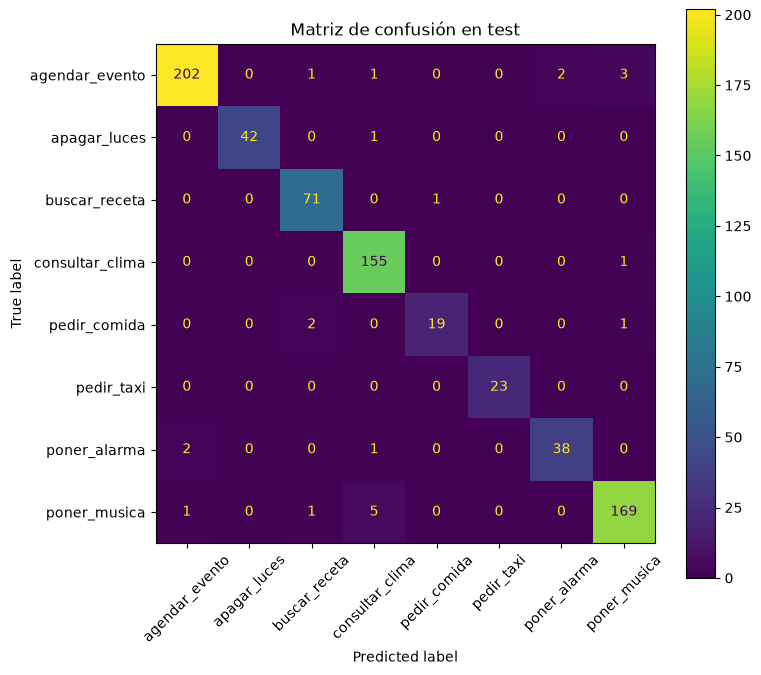

Errores: 23 de 742


,text,intencion,prediccion
21,siete años,poner_musica,agendar_evento
40,conseguir marcas,consultar_clima,poner_musica
73,abre la carpeta de aplicaciones por favor,pedir_comida,poner_musica
118,quiero comer algo picante,pedir_comida,buscar_receta
135,me voy a dormir ahora,apagar_luces,consultar_clima
163,por favor pon la alamar para el próximo viernes a las seis y media de la mañana,poner_alarma,agendar_evento
191,es hora de comida basura,pedir_comida,buscar_receta
308,establecer una notificación para el juego de deportes,agendar_evento,poner_musica
339,nadie lo sabe,poner_musica,consultar_clima
358,s,poner_musica,consultar_clima


In [22]:
trainer_final, tokenizer_final = modelos["train completo"]

# a) Calcula predicciones para test_df
predicciones = predecir_etiquetas(trainer_final, tokenizer_final, test_df)

# b) Dibuja la matriz de confusión con los nombres de las intenciones
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test_df["label"], 
    predicciones, 
    display_labels=list(ETIQUETAS.values()), 
    xticks_rotation=45, 
    ax=ax
)
ax.set_title("Matriz de confusión en test")
plt.tight_layout()
plt.show()

# c) Crea errores: las frases de test_df mal clasificadas
errores = (
    test_df.assign(prediccion=pd.Series(predicciones).map(ETIQUETAS))
    .query("intencion != prediccion")
)

print(f"Errores: {len(errores)} de {len(test_df)}")
errores[["text", "intencion", "prediccion"]].head(15)

Map: 100%|██████████| 742/742 [00:00<00:00, 27633.80 examples/s]
d:\Users\ClientAdm\Documents\datascience-g8\01-python-intro\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


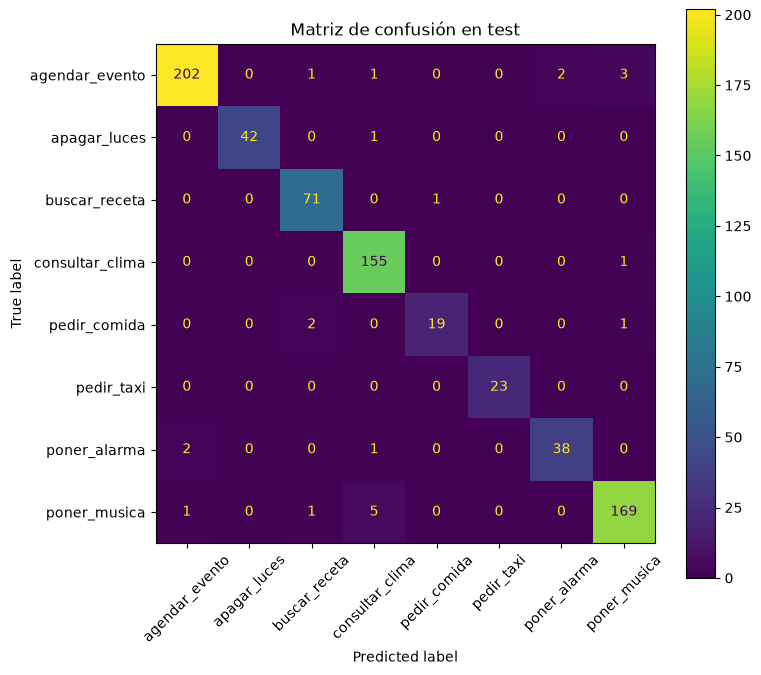

Errores: 23 de 742


,text,intencion,prediccion
0,siete años,poner_musica,agendar_evento
1,conseguir marcas,consultar_clima,poner_musica
2,abre la carpeta de aplicaciones por favor,pedir_comida,poner_musica
3,quiero comer algo picante,pedir_comida,buscar_receta
4,me voy a dormir ahora,apagar_luces,consultar_clima
5,por favor pon la alamar para el próximo viernes a las seis y media de la mañana,poner_alarma,agendar_evento
6,es hora de comida basura,pedir_comida,buscar_receta
7,establecer una notificación para el juego de deportes,agendar_evento,poner_musica
8,nadie lo sabe,poner_musica,consultar_clima
9,s,poner_musica,consultar_clima


In [20]:
trainer_final, tokenizer_final = modelos["train completo"]

# a) Predicciones en test_df
predicciones = predecir_etiquetas(trainer_final, tokenizer_final, test_df)

# b) Matriz de confusión
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    predicciones,
    display_labels=list(ETIQUETAS.values()),
    xticks_rotation=45,
    ax=ax
)
ax.set_title("Matriz de confusión en test")
plt.tight_layout()
plt.show()

# c) Errores: frases mal clasificadas
errores = test_df.assign(
    prediccion=pd.Series(predicciones).map(ETIQUETAS)
)[test_df["label"] != predicciones].reset_index(drop=True)

print(f"Errores: {len(errores)} de {len(test_df)}")
errores[["text", "intencion", "prediccion"]].head(15)

### Ejercicio 7. Guarda el modelo y úsalo

In [23]:
from transformers import pipeline

RUTA_MODELO = "../data/modelo_intenciones"

# Guardar modelo y tokenizador
trainer_final.save_model(RUTA_MODELO)
tokenizer_final.save_pretrained(RUTA_MODELO)

# Cargar clasificador
clasificador = pipeline("text-classification", model=RUTA_MODELO, tokenizer=RUTA_MODELO)

mis_frases = [
    "levántame a las 5 que tengo vuelo",
    "pon algo de salsa para cocinar",
    "cómo preparo un lomo saltado",
    "tráeme un pollo a la brasa con papas",
    "necesito un taxi a miraflores",
    "anota la reunión con el contador el viernes",
    "¿hará frío esta noche en cusco?",
    "cuánto es 25 por 4",
    "cuéntame un chiste",
    "¿quién ganó el partido de ayer?",
]

for texto in mis_frases:
    resultado = clasificador(texto)[0]
    print(f"{resultado['label']:>16} ({resultado['score']:.2f})  {texto}")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 746.83it/s]


    poner_alarma (0.82)  levántame a las 5 que tengo vuelo
   buscar_receta (0.98)  pon algo de salsa para cocinar
   buscar_receta (0.99)  cómo preparo un lomo saltado
   buscar_receta (0.99)  tráeme un pollo a la brasa con papas
      pedir_taxi (0.99)  necesito un taxi a miraflores
  agendar_evento (1.00)  anota la reunión con el contador el viernes
 consultar_clima (0.99)  ¿hará frío esta noche en cusco?
 consultar_clima (0.99)  cuánto es 25 por 4
   buscar_receta (0.38)  cuéntame un chiste
 consultar_clima (0.65)  ¿quién ganó el partido de ayer?


In [24]:
#C)
def responder(texto, umbral=0.7):
    resultado = clasificador(texto)[0]
    if resultado["score"] < umbral:
        return "no_entendi"
    else:
        return resultado["label"]

for texto in mis_frases:
    print(f"{responder(texto):>16}  {texto}")

    poner_alarma  levántame a las 5 que tengo vuelo
   buscar_receta  pon algo de salsa para cocinar
   buscar_receta  cómo preparo un lomo saltado
   buscar_receta  tráeme un pollo a la brasa con papas
      pedir_taxi  necesito un taxi a miraflores
  agendar_evento  anota la reunión con el contador el viernes
 consultar_clima  ¿hará frío esta noche en cusco?
 consultar_clima  cuánto es 25 por 4
      no_entendi  cuéntame un chiste
      no_entendi  ¿quién ganó el partido de ayer?
